<a href="https://colab.research.google.com/github/AlessiaSerra/Clickbait-Detection/blob/main/File.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
pip install datasets pandas scikit-learn numpy

In [25]:
# ===================== 0. IMPORT + CONFIGURAZIONE =====================
import os, re, json, lzma, zlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import hstack
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
import math
warnings.filterwarnings("ignore")

SEED = 42
DATA_DIRS = ["/content"]
HEADLINE_FIELD = "postText"
SAMPLE_SIZE = 5000
BODY_MAX_CHARS = 20000
LOWERCASE = True
COMPRESSOR = "zlib"             # "lzma" or "zlib"
BG_POOL_SIZE = 500              # articles to be used only for the background
BG_N_BODIES, BG_BODY_CHARS, BG_N_HEADLINES = 30, 300, 150


In [26]:
# Computation of complexity and unexpectedness
def zlen(data: bytes, method="lzma") -> int:
    """We compress without taking into account header/trailer"""
    if method == "lzma":
        return len(lzma.compress(data, format=lzma.FORMAT_RAW,
                                 filters=[{"id": lzma.FILTER_LZMA2, "preset": 9, "dict_size": 1 << 17}]))
    if method == "zlib":
        c = zlib.compressobj(9, zlib.DEFLATED, -15, 9)
        return len(c.compress(data) + c.flush())
    raise ValueError(method)

class AITComplexityEngine:
    """
    C_d = K(title | background)
    C_w = K(title | background + body)
    U   = C_w - C_d  (<= ~0)
    U_norm = U / title_length ; R = C_w / C_d
    """
    def __init__(self, background: str, method: str = "lzma"):
        self.bg, self.method = background.encode("utf-8"), method
        self.z_bg = zlen(self.bg, method)

    def get_cd(self, title: str) -> int:
        t = title.encode("utf-8")
        return max(zlen(self.bg + b"\n" + t, self.method) - self.z_bg, 1)

    def get_cw(self, title: str, body: str) -> int:
        ctx = self.bg + b"\n" + body.encode("utf-8")
        z_ctx = zlen(ctx, self.method)
        z_combined = zlen(ctx + b"\n" + title.encode("utf-8"), self.method)
        return max(z_combined - z_ctx, 0)

    def compute_metrics(self, title: str, body: str) -> tuple:
        cd = self.get_cd(title)
        cw = self.get_cw(title, body)
        u = cw - cd
        u_norm = u / (len(title) + 1e-5)
        r = cw / cd
        return cd, cw, u, u_norm, r


In [27]:
# Loading Webis Clickbait Challenge 2017 dataset (Title + Body)
def read_jsonl(path, keys):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                d = json.loads(line)
                rows.append({k: d.get(k) for k in keys})
    return pd.DataFrame(rows)

def as_text(x):
    if isinstance(x, list):
        return " ".join(str(i) for i in x)
    return "" if x is None else str(x)

def clean(s):
    s = re.sub(r"https?://\S+|@\w+", " ", s).replace("#", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s.lower() if LOWERCASE else s

parts = []
for d in DATA_DIRS:
    ip, tp = os.path.join(d, "instances.jsonl"), os.path.join(d, "truth.jsonl")
    inst = read_jsonl(ip, ["id", "postText", "targetTitle", "targetParagraphs"])
    truth = read_jsonl(tp, ["id", "truthClass", "truthMean"])
    inst["id"], truth["id"] = inst["id"].astype(str), truth["id"].astype(str)
    parts.append(inst.merge(truth, on="id"))
df_raw = pd.concat(parts, ignore_index=True).drop_duplicates("id")

title_col, body_col, label_col = "title", "text", "label"
df_raw[title_col] = df_raw[HEADLINE_FIELD].map(as_text).map(clean)
df_raw[body_col] = df_raw["targetParagraphs"].map(as_text).map(clean).str[:BODY_MAX_CHARS]
df_raw[label_col] = (df_raw["truthClass"] == "clickbait").astype(int)
df_raw = df_raw[(df_raw[title_col].str.len() >= 10) & (df_raw[body_col].str.len() >= 200)]
df_raw = df_raw[["id", title_col, body_col, label_col, "truthMean"]].sample(frac=1.0, random_state=SEED).reset_index(drop=True)
#print(len(df_raw), "examples | % clickbait:", round(df_raw[label_col].mean() * 100, 1))

# For background
pool, rest = df_raw.iloc[:BG_POOL_SIZE], df_raw.iloc[BG_POOL_SIZE:]
BACKGROUND = ("\n".join(pool[body_col].sample(min(BG_N_BODIES, len(pool)), random_state=SEED).str[:BG_BODY_CHARS]) + "\n" +
              "\n".join(pool[title_col].sample(min(BG_N_HEADLINES, len(pool)), random_state=SEED)))

# Sample in a balanced way
half = min(SAMPLE_SIZE // 2, rest[label_col].value_counts().min())
df_cb = rest[rest[label_col] == 1].sample(half, random_state=SEED)
df_non_cb = rest[rest[label_col] == 0].sample(half, random_state=SEED)
df = pd.concat([df_cb, df_non_cb]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

train_df, test_df = train_test_split(df, test_size=0.3, random_state=SEED, stratify=df[label_col])
engine = AITComplexityEngine(BACKGROUND, COMPRESSOR)
#print("Background:", len(BACKGROUND), "caratteri | train:", len(train_df), "| test:", len(test_df))


-Feature extraction on Train Set-


  0%|          | 0/3500 [00:00<?, ?it/s]

-Feature extraction on Test Set-


  0%|          | 0/1500 [00:00<?, ?it/s]


--------------------------------------------------
ANALYSIS: Unexpectedness vs Label
           C_d                        C_w                         U                     U_norm                             R                    
          mean        std median     mean       std median     mean       std median      mean       std    median      mean       std    median
label                                                                                                                                           
0      34.3476   8.983889   34.0  22.4048  7.729841   22.0 -11.9428  8.075792  -11.0 -0.158729  0.089883 -0.150685  0.665809  0.183505  0.678571
1      27.8176  10.917619   28.0  20.6212  9.200977   20.0  -7.1964  7.631692   -6.0 -0.108740  0.113580 -0.093023  0.770143  0.212948  0.800000

--------------------------------------------------
Pearson Correlation (U, Label):  0.2892 (p-value: 6.2347e-97)
Spearman Correlation (U, Label): 0.3515 (p-value: 2.2114e-145)
Two-sample t

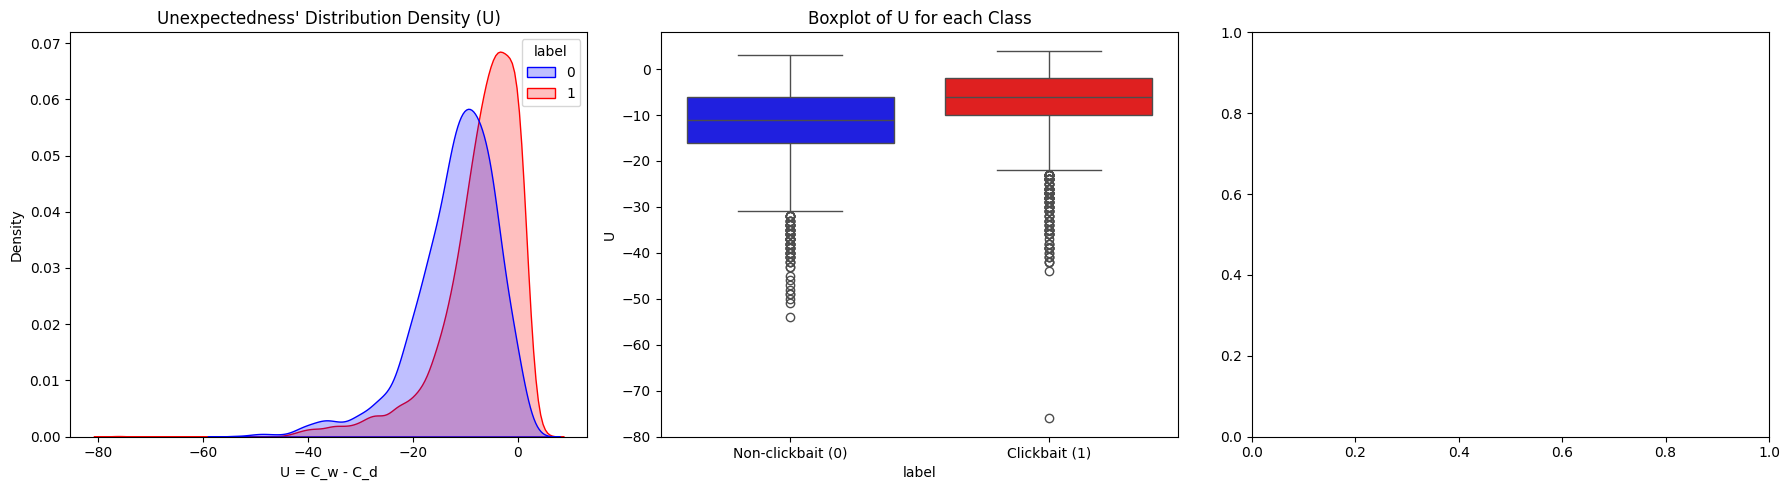

In [28]:
# Feature extraction
def extract_ait_features(dataset, engine=engine):
    cd_l, cw_l, u_l, un_l, r_l = [], [], [], [], []
    for t, b in tqdm(zip(dataset[title_col].astype(str), dataset[body_col].astype(str)), total=len(dataset)):
        cd, cw, u, u_norm, r = engine.compute_metrics(t, b)
        cd_l.append(cd); cw_l.append(cw); u_l.append(u); un_l.append(u_norm); r_l.append(r)
    dataset = dataset.copy()
    dataset["C_d"], dataset["C_w"], dataset["U"], dataset["U_norm"], dataset["R"] = cd_l, cw_l, u_l, un_l, r_l

    # useful to show that everything is not only based on length
    dataset["title_length"] = dataset[title_col].astype(str).str.len()
    dataset["title_words"] = dataset[title_col].astype(str).str.split().str.len()
    dataset["body_length"] = dataset[body_col].astype(str).str.len()
    return dataset

print("-Feature extraction on Train Set-")
train_df = extract_ait_features(train_df)
print("-Feature extraction on Test Set-")
test_df = extract_ait_features(test_df)

# Analysis: unexpectedness vs label
df_eda = pd.concat([train_df, test_df]).reset_index(drop=True)
print("\n" + "-" * 50)
print("ANALYSIS: Unexpectedness vs Label")
summary = df_eda.groupby(label_col)[["C_d", "C_w", "U", "U_norm", "R"]].agg(["mean", "std", "median"])
print(summary.to_string())

corr_pearson, p_pearson = stats.pearsonr(df_eda["U"], df_eda[label_col])
corr_spearman, p_spearman = stats.spearmanr(df_eda["U"], df_eda[label_col])
t_stat, t_pval = stats.ttest_ind(df_eda[df_eda[label_col] == 1]["U"], df_eda[df_eda[label_col] == 0]["U"])
print("\n" + "-" * 50)
print(f"Pearson Correlation (U, Label):  {corr_pearson:.4f} (p-value: {p_pearson:.4e})")
print(f"Spearman Correlation (U, Label): {corr_spearman:.4f} (p-value: {p_spearman:.4e})")
print(f"Two-sample t-test su U: t = {t_stat:.4f}, p-value = {t_pval:.4e}")

def partial_spearman(d, x, y, controls):
    """Partial Spearman on x,y checking 'controls' variables."""
    r = d[[x, y] + controls].rank()
    Z = np.column_stack([np.ones(len(r))] + [r[c].values for c in controls])
    res = lambda v: v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]
    return stats.pearsonr(res(r[x].values), res(r[y].values))

print("\nPartial correlation with label:")
for f in ["U", "U_norm", "R"]:
    r, p = partial_spearman(df_eda, f, label_col, ["title_length", "body_length"])
    print(f"  {f}: r = {r:.4f} (p = {p:.2e})")

d2 = df_eda.dropna(subset=["truthMean"])
if len(d2):
    print("\nSpearman with truthMean:")
    for f in ["U", "U_norm", "R"]:
        rho, p = stats.spearmanr(d2[f], d2["truthMean"])
        print(f"  {f}: rho = {rho:.4f} (p = {p:.2e})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
safe_palette = {0: "blue", 1: "red", "0": "blue", "1": "red"}

# Plots: U distribution and boxplot
sns.kdeplot(data=df_eda, x="U", hue=label_col, common_norm=False, fill=True, palette=safe_palette, ax=axes[0])
axes[0].set_title("Unexpectedness' Distribution Density (U)")
axes[0].set_xlabel("U = C_w - C_d")

sns.boxplot(data=df_eda, x=label_col, y="U", hue=label_col, palette=safe_palette, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Non-clickbait (0)", "Clickbait (1)"])
axes[1].set_title("Boxplot of U for each Class")

# Plot 3: spazio C_d vs C_w
# sns.scatterplot(data=df_eda.sample(min(2000, len(df_eda)), random_state=SEED), x="C_d", y="C_w",
#                 hue=label_col, alpha=0.6, palette=safe_palette, ax=axes[2])
# axes[2].axline((0, 0), slope=1, color="gray", linestyle="--", label="C_w = C_d (U=0)")
# axes[2].set_title("Phase Space AIT: C_d vs C_w")
# axes[2].legend()
plt.tight_layout()
plt.show()



INIZIO MULTI-MODEL SELECTION (AIT Base & Esteso)

--- Ottimizzazione su set feature: AIT Base ---
Tuning Gradient Boosting...
   Best AUC CV: 0.6545 | Parametri: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}

--- Ottimizzazione su set feature: AIT Ext ---
Tuning Gradient Boosting...
   Best AUC CV: 0.6544 | Parametri: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}

FINAL BENCHMARK ON TEST SET (Sorted by ROC-AUC)
                       Model  Accuracy  F1-Score  ROC-AUC
  Hybrid (TF-IDF + AIT Base)    0.7100    0.7043   0.7752
          Full Text (TF-IDF)    0.6967    0.6924   0.7554
 Gradient Boosting (AIT Ext)    0.6687    0.6385   0.7271
Gradient Boosting (AIT Base)    0.6600    0.6492   0.7082
            Baseline: Length    0.6233    0.5879   0.6652


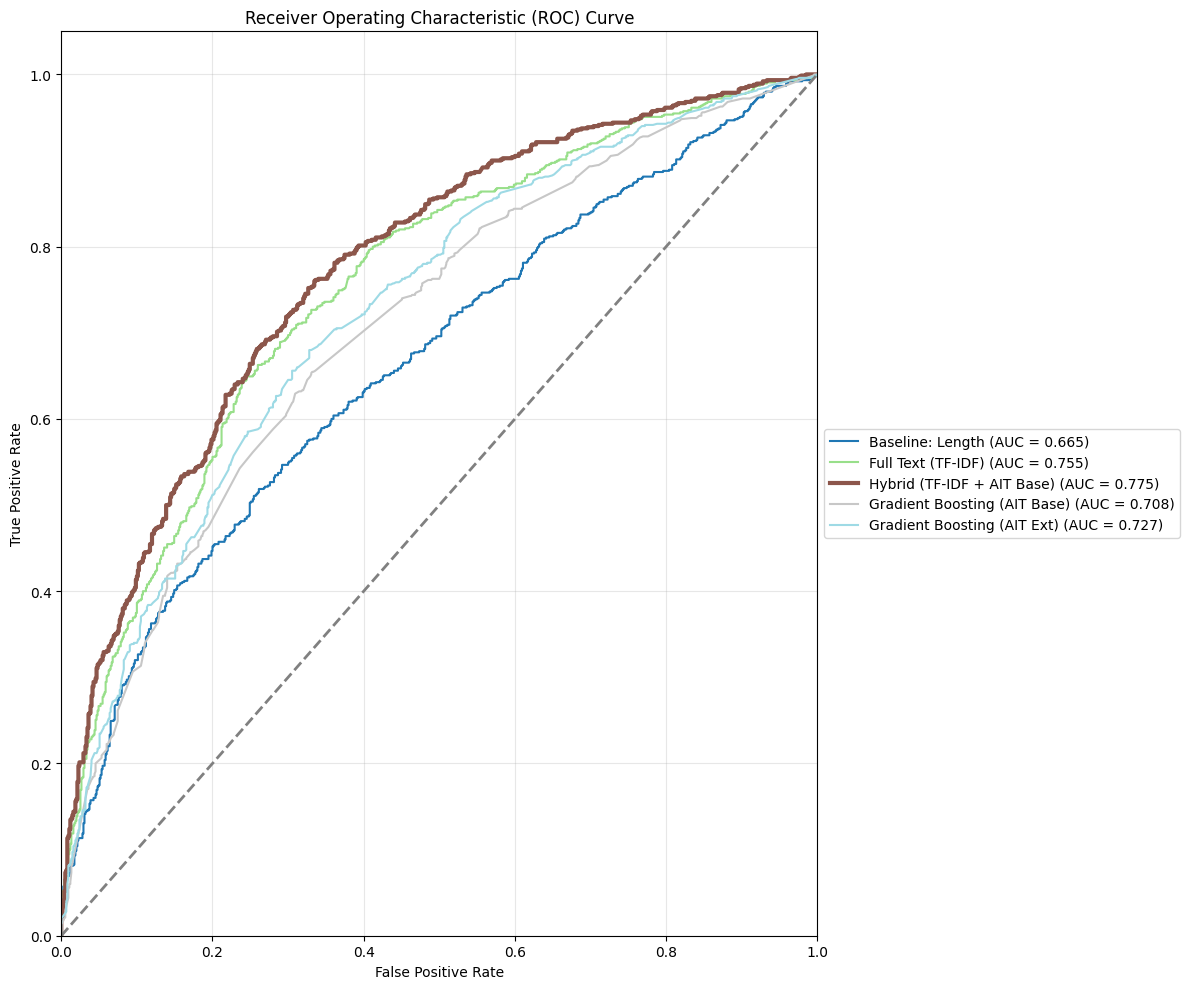

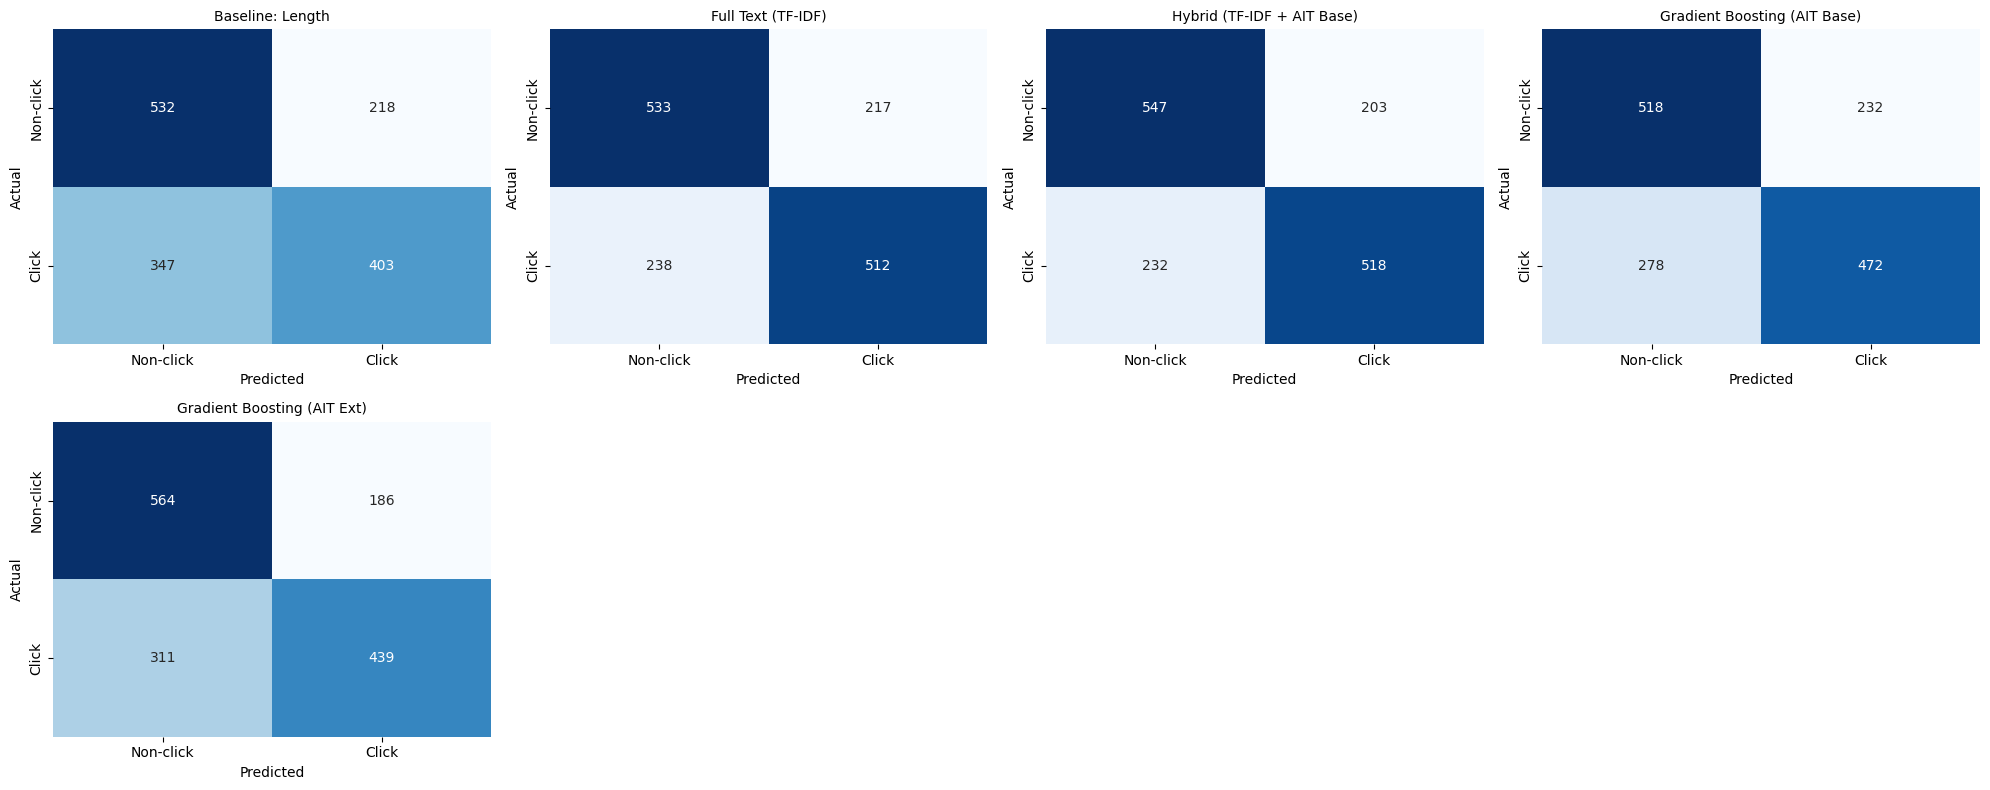

In [29]:
# Clickbait detection algorithm
ait_features = ["U", "U_norm"]
length_features = ["title_length", "title_words", "body_length"]      # controllo: baseline "solo lunghezza"
X_train_ait, X_test_ait = train_df[ait_features], test_df[ait_features]
X_train_len, X_test_len = train_df[length_features], test_df[length_features]
y_train, y_test = train_df[label_col], test_df[label_col]

# AIT with Random Forest (detector puramente AIT)
rf_ait = RandomForestClassifier(random_state=SEED, class_weight="balanced", max_depth= 10, min_samples_leaf= 10, min_samples_split= 2, n_estimators= 200)
rf_ait.fit(X_train_ait, y_train)
test_preds_rf = rf_ait.predict(X_test_ait)

# AIT with KNN
scaler_knn = StandardScaler()
X_train_ait_scaled = scaler_knn.fit_transform(X_train_ait)
X_test_ait_scaled = scaler_knn.transform(X_test_ait)
knn_ait = KNeighborsClassifier(n_neighbors=25, weights="distance")   # k piu' alto: meno overfitting su feature rumorose
knn_ait.fit(X_train_ait_scaled, y_train)
test_preds_knn = knn_ait.predict(X_test_ait_scaled)

# Controllo: solo lunghezza (Random Forest)
rf_len = RandomForestClassifier(n_estimators=200, random_state=SEED, class_weight="balanced", min_samples_leaf=5)
rf_len.fit(X_train_len, y_train)
preds_len = rf_len.predict(X_test_len)

# Random model
dummy_strat = DummyClassifier(strategy="stratified", random_state=SEED)
dummy_strat.fit(X_train_ait, y_train)
preds_strat = dummy_strat.predict(X_test_ait)

# "Classical method" (TF-IDF + Logistic Regression) ON FULL TEXT (Title + Body)
tfidf = TfidfVectorizer(max_features=3000, stop_words="english")
train_full_text = train_df[title_col].astype(str) + " " + train_df[body_col].astype(str)
test_full_text = test_df[title_col].astype(str) + " " + test_df[body_col].astype(str)
X_train_tfidf = tfidf.fit_transform(train_full_text)
X_test_tfidf = tfidf.transform(test_full_text)
lr_model = GradientBoostingClassifier(random_state=SEED)
lr_model.fit(X_train_tfidf, y_train)
preds_lr = lr_model.predict(X_test_tfidf)

# Hybrid model (TF-IDF + Scaled AIT)
scaler_hybrid = MaxAbsScaler()
X_train_hybrid = hstack([X_train_tfidf, scaler_hybrid.fit_transform(X_train_ait)]).tocsr()
X_test_hybrid = hstack([X_test_tfidf, scaler_hybrid.transform(X_test_ait)]).tocsr()
lr_hybrid = GradientBoostingClassifier(random_state=SEED)
lr_hybrid.fit(X_train_hybrid, y_train)
preds_hybrid = lr_hybrid.predict(X_test_hybrid)

###############################


# ===================== MULTI-MODEL SELECTION =====================
print("\n" + "="*60)
print("INIZIO MULTI-MODEL SELECTION (AIT Base & Esteso)")
print("="*60)

# 1. Definiamo i modelli e gli iperparametri da esplorare (aggiunto il prefisso 'clf__' richiesto dalla Pipeline)
classifiers = {

    "Gradient Boosting": (
        Pipeline([('scaler', StandardScaler()), ('clf', GradientBoostingClassifier(random_state=SEED))]),
        {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [3, 5]}
    )
}

# 2. Definiamo i due set di feature AIT
extended_ait_features = ["U", "U_norm", "C_w", "C_d"]
X_train_ait_ext = train_df[extended_ait_features]
X_test_ait_ext = test_df[extended_ait_features]

feature_sets = {
    "Base": (X_train_ait, X_test_ait),
    "Ext": (X_train_ait_ext, X_test_ait_ext)
}

# 3. Dizionari per salvare le nuove predizioni
tuned_preds = {}
tuned_probs = {}

# 4. Loop di addestramento e validazione
for set_name, (X_tr, X_te) in feature_sets.items():
    print(f"\n--- Ottimizzazione su set feature: AIT {set_name} ---")
    for clf_name, (pipeline, param_grid) in classifiers.items():
        print(f"Tuning {clf_name}...")

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            cv=3,                 # Abbassato a 3 per velocizzare, mettilo a 5 se hai tempo
            scoring='f1_macro',
            n_jobs=-1,
            verbose=0
        )
        grid.fit(X_tr, y_train)

        best_model = grid.best_estimator_
        model_key = f"{clf_name} (AIT {set_name})"

        print(f"   Best AUC CV: {grid.best_score_:.4f} | Parametri: {grid.best_params_}")

        # Salvataggio predizioni e probabilità
        tuned_preds[model_key] = best_model.predict(X_te)
        tuned_probs[model_key] = best_model.predict_proba(X_te)[:, 1]

# ===================== AGGIORNAMENTO DIZIONARI ORIGINALI =====================

# Inizializziamo i modelli baseline come avevi fatto tu
models = {
    "Baseline: Length": preds_len,
    "Full Text (TF-IDF)": preds_lr,
    "Hybrid (TF-IDF + AIT Base)": preds_hybrid,
}

model_probs = {
    "Baseline: Length": rf_len.predict_proba(X_test_len)[:, 1],
    "Full Text (TF-IDF)": lr_model.predict_proba(X_test_tfidf)[:, 1],
    "Hybrid (TF-IDF + AIT Base)": lr_hybrid.predict_proba(X_test_hybrid)[:, 1],
}

# Uniamo le baseline con i nuovi modelli ottimizzati
models.update(tuned_preds)
model_probs.update(tuned_probs)

# ===================== BENCHMARK & GRAFICI =====================

benchmark_records = []
for name, preds in models.items():
    benchmark_records.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, model_probs[name]), 4),
    })

df_benchmark = pd.DataFrame(benchmark_records).sort_values(by="ROC-AUC", ascending=False)
print("\n" + "="*70)
print("FINAL BENCHMARK ON TEST SET (Sorted by ROC-AUC)")
print("="*70)
print(df_benchmark.to_string(index=False))

# --- ROC Curve ---
plt.figure(figsize=(12, 10))
# Usiamo una colormap per distinguere meglio le tante linee
colors = plt.cm.tab20(np.linspace(0, 1, len(model_probs)))
for (name, prob), color in zip(model_probs.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, prob)
    # Evidenzia l'ibrido e i migliori
    lw = 3 if "Hybrid" in name else 1.5
    plt.plot(fpr, tpr, lw=lw, color=color, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], color="gray", lw=2, linestyle="--")
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
# Sposta la legenda fuori dal grafico se ci sono troppi modelli
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- Confusion Matrix (Dinamica) ---
n_models = len(models)
cols = 4 # 4 grafici per riga
rows = math.ceil(n_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = axes.flatten()

for idx, (name, preds) in enumerate(models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx], cbar=False,
                xticklabels=["Non-click", "Click"], yticklabels=["Non-click", "Click"])
    axes[idx].set_title(name, fontsize=10)
    axes[idx].set_xlabel("Predicted"); axes[idx].set_ylabel("Actual")

# Nascondi gli assi vuoti in eccesso
for idx in range(n_models, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout(); plt.show()

In [30]:
# Ablation
feature_sets = {
    "Only Cd": ["C_d"],
    "Only Cw": ["C_w"],
    "Only U": ["U"],
    "Only R": ["R"],
    "Cd + Cw": ["C_d", "C_w"],
    "All AIT": ["C_d", "C_w", "U", "U_norm", "R"],
    "Length only (controllo)": length_features,
    "Length + AIT": length_features + ["C_d", "C_w", "U", "U_norm", "R"],
}
for name, features in feature_sets.items():
    model = RandomForestClassifier(n_estimators=200, random_state=SEED, class_weight="balanced", min_samples_leaf=5)
    model.fit(train_df[features], y_train)
    probabilities = model.predict_proba(test_df[features])[:, 1]
    print(f"{name}: ROC-AUC = {roc_auc_score(y_test, probabilities):.4f}")


Only Cd: ROC-AUC = 0.6884
Only Cw: ROC-AUC = 0.5675
Only U: ROC-AUC = 0.6905
Only R: ROC-AUC = 0.6403
Cd + Cw: ROC-AUC = 0.6892
All AIT: ROC-AUC = 0.6937
Length only (controllo): ROC-AUC = 0.6652
Length + AIT: ROC-AUC = 0.7284


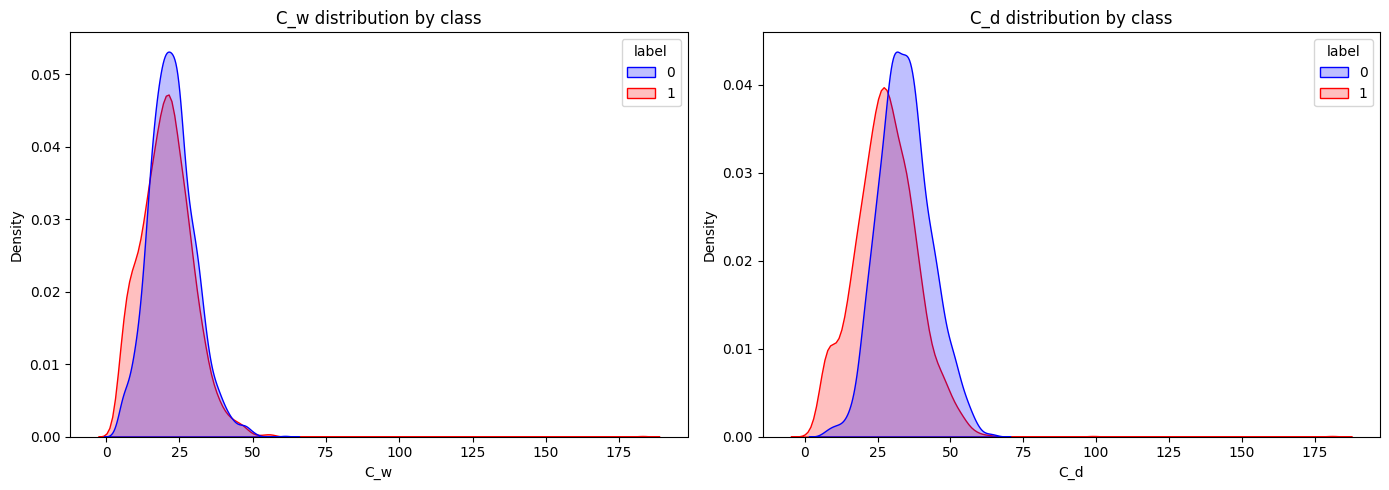

In [31]:
# Cw and Cd distrubution for each class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["C_w", "C_d"]):
    sns.kdeplot(data=df_eda, x=col, hue=label_col, common_norm=False, fill=True,
                palette={0: "blue", 1: "red"}, ax=ax)
    ax.set_title(f"{col} distribution by class")
plt.tight_layout(); plt.show()


In [32]:
# Correlation with lengths (confound) + label correlation
print(df_eda[["C_w", "C_d", "U", "R", "title_length", "body_length", label_col]].corr(method="spearman").round(3))


                C_w    C_d      U      R  title_length  body_length  label
C_w           1.000  0.617  0.129  0.397         0.590       -0.011 -0.112
C_d           0.617  1.000 -0.618 -0.352         0.926       -0.011 -0.319
U             0.129 -0.618  1.000  0.935        -0.552       -0.020  0.352
R             0.397 -0.352  0.935  1.000        -0.303       -0.019  0.289
title_length  0.590  0.926 -0.552 -0.303         1.000        0.017 -0.296
body_length  -0.011 -0.011 -0.020 -0.019         0.017        1.000  0.045
label        -0.112 -0.319  0.352  0.289        -0.296        0.045  1.000


In [33]:
# Compressors benchmark
sub = df_eda.sample(min(1000, len(df_eda)), random_state=SEED)[[title_col, body_col, label_col]]
for method in ["lzma", "zlib"]:
    eng = AITComplexityEngine(BACKGROUND, method)
    d = extract_ait_features(sub, eng)
    print(f"{method}: Spearman U={stats.spearmanr(d.U, d[label_col])[0]:.3f}  R={stats.spearmanr(d.R, d[label_col])[0]:.3f} | "
          f"AUC U={roc_auc_score(d[label_col], d.U):.3f}  R={roc_auc_score(d[label_col], d.R):.3f}")


  0%|          | 0/1000 [00:00<?, ?it/s]

lzma: Spearman U=0.302  R=0.240 | AUC U=0.674  R=0.638


  0%|          | 0/1000 [00:00<?, ?it/s]

zlib: Spearman U=0.308  R=0.257 | AUC U=0.678  R=0.649


In [34]:
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report

# 1. Prendi le probabilità generate dal tuo modello sul Test Set
# (Sostituisci 'Gradient Boosting (AIT Ext)' con la chiave esatta del tuo modello)
model_key = "Gradient Boosting (AIT Ext)"
y_probs = model_probs[model_key]

# 2. Definiamo un array di possibili soglie da 0.01 a 0.99
thresholds = np.arange(0.01, 1.0, 0.01)
f1_scores = []

# 3. Calcoliamo l'F1-Score per ogni soglia
for thresh in thresholds:
    preds_at_thresh = (y_probs >= thresh).astype(int)
    f1_scores.append(f1_score(y_test, preds_at_thresh))

# 4. Troviamo la soglia che massimizza l'F1-Score
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Soglia Ottimale: {best_thresh:.2f}")
print(f"Miglior F1-Score ottenuto: {best_f1:.4f} (Prima era: 0.6385)")

# 5. Generiamo il nuovo report di classificazione con la soglia ottima
final_preds = (y_probs >= best_thresh).astype(int)
print("\n--- Report di Classificazione con Soglia Ottimizzata ---")
print(classification_report(y_test, final_preds, target_names=["Non-click", "Click"]))


Soglia Ottimale: 0.33
Miglior F1-Score ottenuto: 0.7057 (Prima era: 0.6385)

--- Report di Classificazione con Soglia Ottimizzata ---
              precision    recall  f1-score   support

   Non-click       0.75      0.44      0.55       750
       Click       0.60      0.85      0.71       750

    accuracy                           0.64      1500
   macro avg       0.67      0.64      0.63      1500
weighted avg       0.67      0.64      0.63      1500



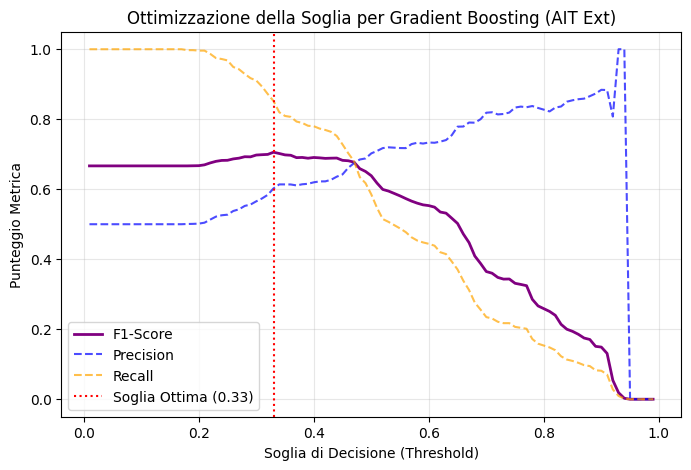

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores, label="F1-Score", color="purple", lw=2)

# Calcoliamo anche Precision e Recall per il grafico
precisions = [precision_score(y_test, (y_probs >= t).astype(int), zero_division=0) for t in thresholds]
recalls = [recall_score(y_test, (y_probs >= t).astype(int), zero_division=0) for t in thresholds]

plt.plot(thresholds, precisions, label="Precision", linestyle="--", color="blue", alpha=0.7)
plt.plot(thresholds, recalls, label="Recall", linestyle="--", color="orange", alpha=0.7)

plt.axvline(best_thresh, color="red", linestyle=":", label=f"Soglia Ottima ({best_thresh:.2f})")
plt.xlabel("Soglia di Decisione (Threshold)")
plt.ylabel("Punteggio Metrica")
plt.title(f"Ottimizzazione della Soglia per {model_key}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


RICERCA SOGLIE OTTIMALI IN CORSO...
-> Gradient Boosting (AIT Base): Soglia Ottima = 0.34 | Nuovo F1-Score = 0.6917
-> Gradient Boosting (AIT Ext): Soglia Ottima = 0.33 | Nuovo F1-Score = 0.7057

FINAL BENCHMARK ON TEST SET (Con soglie ottimizzate su Base ed Ext)
                       Model  Accuracy  F1-Score  ROC-AUC
  Hybrid (TF-IDF + AIT Base)    0.7100    0.7043   0.7752
          Full Text (TF-IDF)    0.6967    0.6924   0.7554
 Gradient Boosting (AIT Ext)    0.6447    0.7057   0.7271
Gradient Boosting (AIT Base)    0.6333    0.6917   0.7082
            Baseline: Length    0.6233    0.5879   0.6652


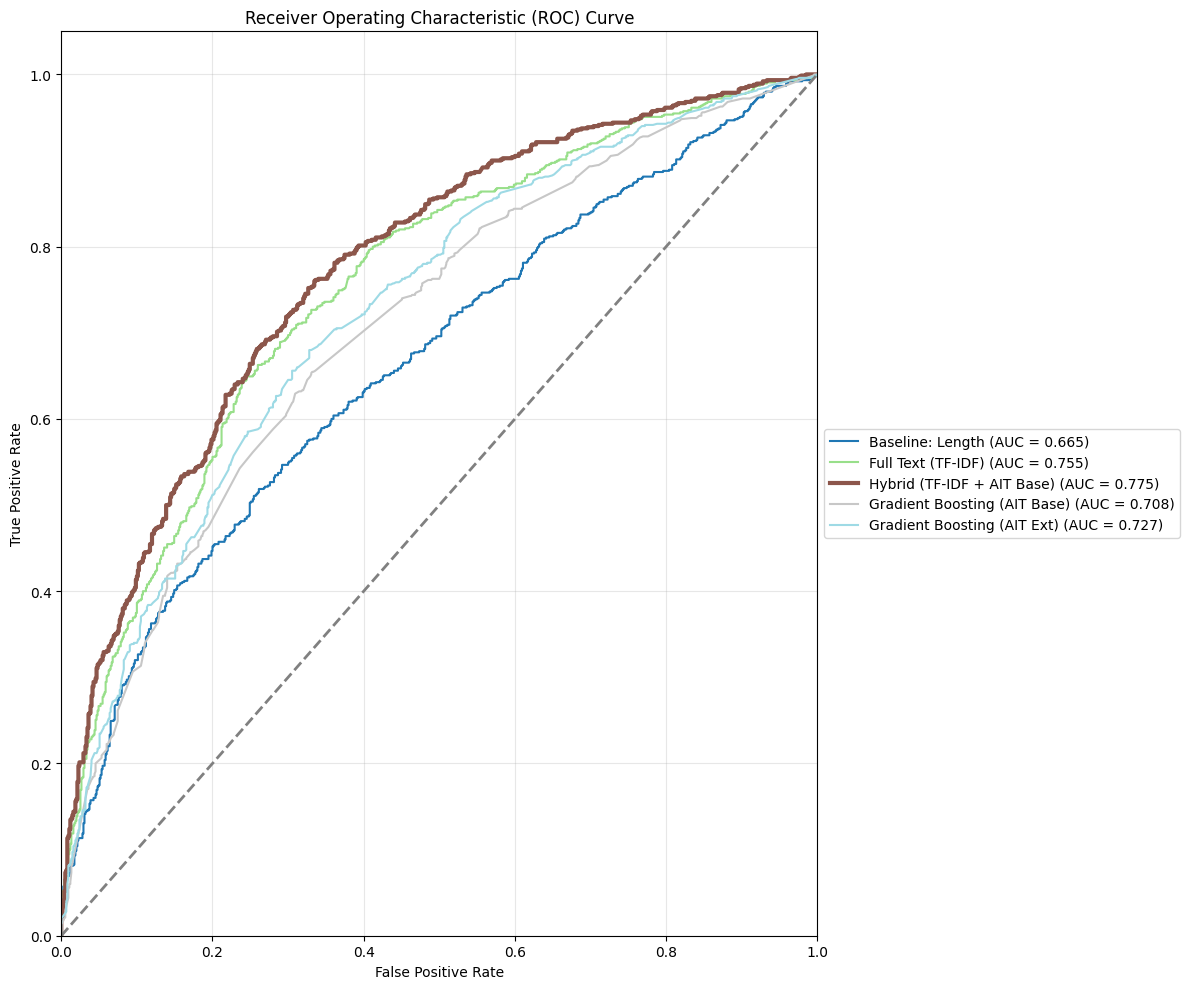

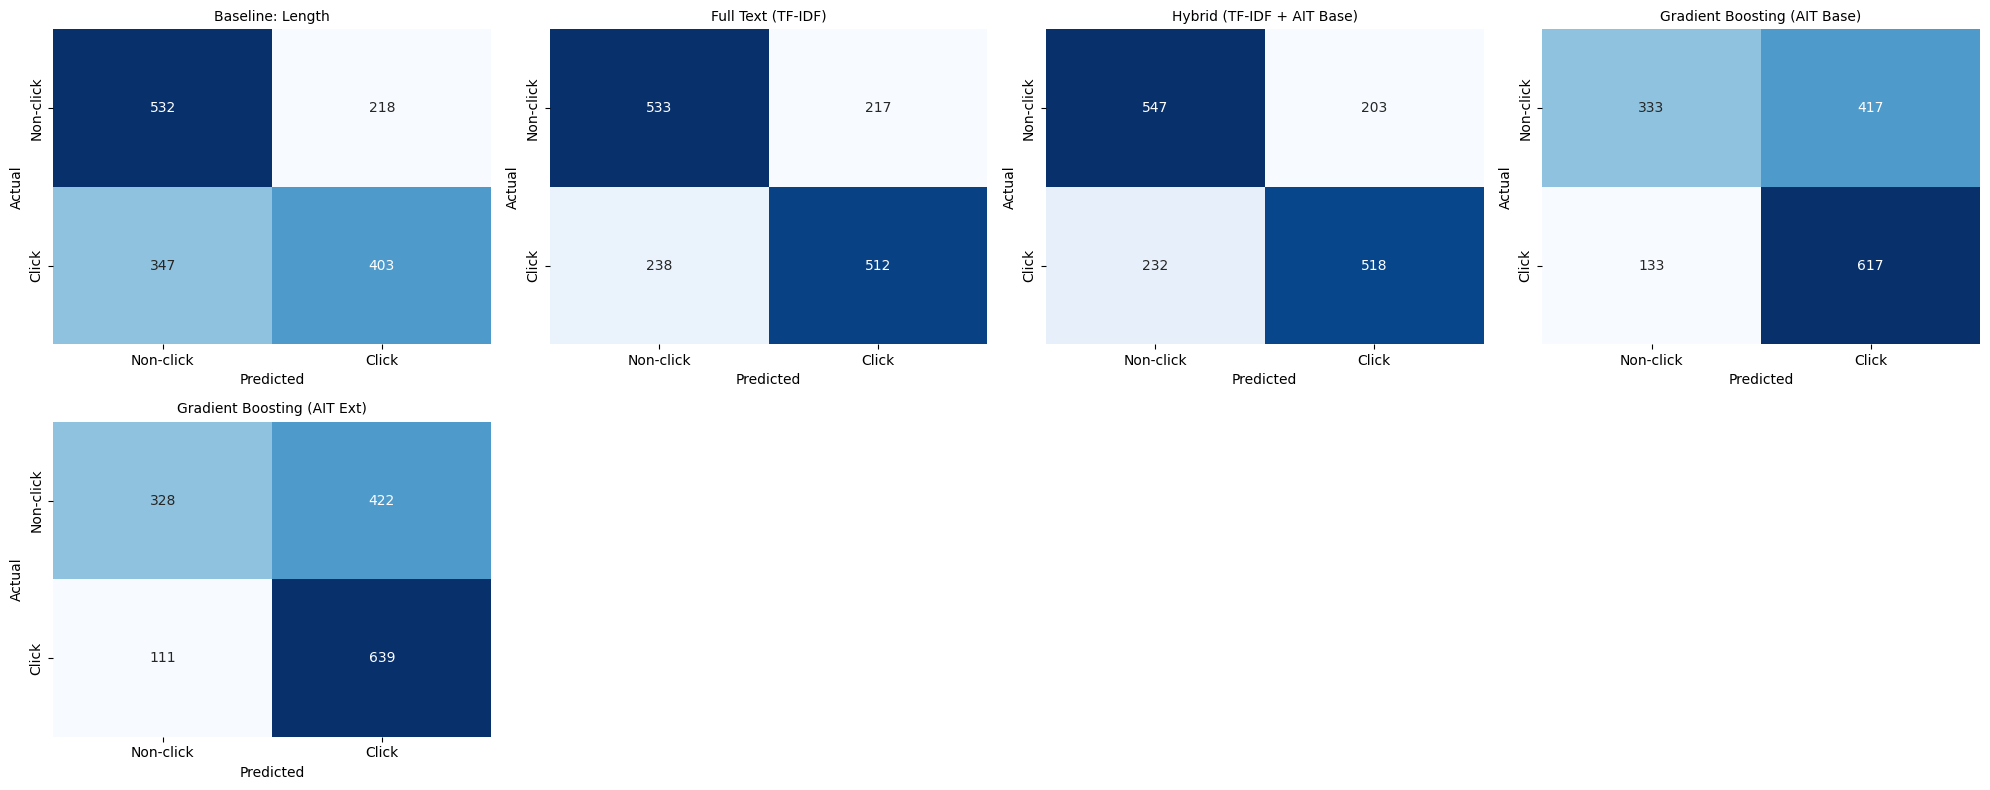

In [36]:
# ==============================================================================
# OTTIMIZZAZIONE AUTOMATICA SOGLIA PER AIT BASE E AIT EXT + RICALCOLO METRICHE
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, roc_curve, auc, confusion_matrix

# 1. Lista dei modelli AIT su cui vogliamo ottimizzare la soglia
models_to_optimize = ["Gradient Boosting (AIT Base)", "Gradient Boosting (AIT Ext)"]
thresholds = np.arange(0.01, 1.0, 0.01)

print("="*70)
print("RICERCA SOGLIE OTTIMALI IN CORSO...")
print("="*70)

for model_key in models_to_optimize:
    if model_key in model_probs:
        y_probs = model_probs[model_key]

        # Calcoliamo l'F1-score per ogni possibile soglia
        f1_scores = [f1_score(y_test, (y_probs >= t).astype(int)) for t in thresholds]

        # Identifichiamo la soglia migliore per QUESTO specifico modello
        best_idx = np.argmax(f1_scores)
        best_thresh = thresholds[best_idx]
        best_f1 = f1_scores[best_idx]

        print(f"-> {model_key}: Soglia Ottima = {best_thresh:.2f} | Nuovo F1-Score = {best_f1:.4f}")

        # Applichiamo la soglia ottimale aggiornando il dizionario delle predizioni finali
        models[model_key] = (y_probs >= best_thresh).astype(int)


# 2. BLOCCO METRICHE E GRAFICI (Identico al tuo script originale)
benchmark_records = []
for name, preds in models.items():
    benchmark_records.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, model_probs[name]), 4),
    })

df_benchmark = pd.DataFrame(benchmark_records).sort_values(by="ROC-AUC", ascending=False)
print("\n" + "="*70)
print("FINAL BENCHMARK ON TEST SET (Con soglie ottimizzate su Base ed Ext)")
print("="*70)
print(df_benchmark.to_string(index=False))

# --- ROC Curve ---
plt.figure(figsize=(12, 10))
colors = plt.cm.tab20(np.linspace(0, 1, len(model_probs)))
for (name, prob), color in zip(model_probs.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, prob)
    lw = 3 if "Hybrid" in name else 1.5
    plt.plot(fpr, tpr, lw=lw, color=color, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], color="gray", lw=2, linestyle="--")
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- Confusion Matrix ---
n_models = len(models)
cols = 4 # 4 grafici per riga
rows = math.ceil(n_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = axes.flatten()

for idx, (name, preds) in enumerate(models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx], cbar=False,
                xticklabels=["Non-click", "Click"], yticklabels=["Non-click", "Click"])
    axes[idx].set_title(name, fontsize=10)
    axes[idx].set_xlabel("Predicted"); axes[idx].set_ylabel("Actual")

# Nascondi gli assi vuoti in eccesso
for idx in range(n_models, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout(); plt.show()
